# START TREK — Agent PPO (Proximal Policy Optimization)

Objectif : entraîner un agent PPO qui pose le module de `LunarLander-v3` avec un score moyen **≥ 200 sur 100 épisodes consécutifs**, et prouver par les mesures pourquoi il y arrive.

**Plan du notebook**
1. Configuration et reproductibilité
2. Environnement
3. Raison de fin d'épisode
4. Boucle d'épisode et format des logs
5. Baseline : agent aléatoire
6. Environnements vectorisés et autoreset
7. Actor-critic
8. Rollout storage et GAE
9. Loss PPO et mise à jour
10. Hyperparamètres
11. Boucle d'entraînement
12. Courbes d'entraînement
13. Sauvegarde du modèle
14. *(à venir)* Évaluation sur 100 épisodes, multi-seeds, expérience comparative, comparaison avec DQN, conclusion

## 1. Configuration et reproductibilité

`TRAIN` contrôle les cellules d'entraînement : à `False`, le notebook recharge les résultats déjà exportés dans `results/ppo/` et `models/` au lieu de réentraîner. Cela permet un *Restart & Run All* rapide pour la relecture et la soutenance.

`SEEDS` est la liste commune fixée avec Tom pour les résultats multi-seeds.

In [1]:
import json
import random
import time
from collections import Counter
from pathlib import Path

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch

# Paramètres globaux
TRAIN = False                     # False : recharger les résultats au lieu de réentraîner
SEEDS = [0, 1, 2]                 # seeds communes (contrat)
ENV_ID = "LunarLander-v3"
RESULTS_DIR = Path("results/ppo")
MODELS_DIR = Path("models")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | numpy {np.__version__}")

gymnasium 1.4.0 | torch 2.14.1 | numpy 2.5.4


In [2]:
def set_seed(seed):
    """Fixe toutes les sources d'aléatoire côté Python, NumPy et PyTorch.

    Les seeds de l'environnement se passent à part : env.reset(seed=...) et env.action_space.seed(...).
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

## 2. Environnement

Deux usages, deux modes de rendu :
- **entraînement et évaluation chiffrée** : `render_mode=None`, aucun affichage, c'est le plus rapide ;
- **visualisation** : `render_mode="human"` ouvre une fenêtre, à n'utiliser que pour regarder l'agent jouer.

La taille de l'état et le nombre d'actions sont lus depuis l'environnement, jamais codés en dur.

In [3]:
def make_env(render_mode=None):
    """Crée un environnement LunarLander (render_mode=None pour entraîner, "human" pour regarder)."""
    return gym.make(ENV_ID, render_mode=render_mode)


env = make_env()
OBS_DIM = env.observation_space.shape[0]
N_ACTIONS = env.action_space.n
print(f"Espace d'observation : {env.observation_space}")
print(f"Espace d'actions     : {env.action_space}")
print(f"OBS_DIM = {OBS_DIM}, N_ACTIONS = {N_ACTIONS}")
env.close()

Espace d'observation : Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espace d'actions     : Discrete(4)
OBS_DIM = 8, N_ACTIONS = 4


## 3. Raison de fin d'épisode

Gymnasium ne dit pas *pourquoi* un épisode s'est terminé. Les quatre labels du contrat sont `crash`, `out_of_viewport`, `at_rest` et `truncated`.

En lisant le code de `LunarLander`, on voit qu'au step final l'environnement **remplace** la reward par une valeur fixe : `-100` en cas de crash ou de sortie du cadre, `+100` quand le module s'immobilise. La position `x` (indice 0 de l'observation) distingue ensuite la sortie du cadre (`|x| ≥ 1`) du crash.

On en déduit une règle qui n'utilise que `(obs, reward, terminated, truncated)` :

| Condition | Raison |
| --- | --- |
| `terminated` et `abs(x) ≥ 1` | `out_of_viewport` |
| `terminated` et `reward > 0` | `at_rest` |
| `terminated` sinon | `crash` |
| `truncated` (sans `terminated`) | `truncated` |

Elle ne lit pas `env.unwrapped`, donc elle marche telle quelle avec des environnements vectorisés (section 6), où l'état interne de chaque copie est difficile d'accès.

In [4]:
END_REASONS = ["crash", "out_of_viewport", "at_rest", "truncated"]


def get_end_reason(obs, reward, terminated, truncated):
    """Déduit la raison de fin d'un épisode depuis le dernier step.

    Renvoie None si l'épisode continue.
    """
    if terminated:
        if abs(obs[0]) >= 1.0:
            return "out_of_viewport"
        return "at_rest" if reward > 0 else "crash"
    if truncated:
        return "truncated"
    return None

**Vérification de la règle.** On la compare à la vérité terrain lue dans l'état interne de l'environnement (`lander.awake`, `game_over`), sur des épisodes joués :
- par un agent aléatoire, qui produit surtout des crashs et des sorties du cadre ;
- par le contrôleur heuristique fourni avec Gymnasium, qui produit surtout des atterrissages. Il ne sert qu'à ce test : ce n'est pas notre agent.

In [5]:
from gymnasium.envs.box2d.lunar_lander import heuristic


def true_end_reason(env, obs, terminated, truncated):
    """Raison de fin lue dans l'état interne de l'environnement (vérité terrain, test uniquement)."""
    lander_env = env.unwrapped
    if terminated:
        if not lander_env.lander.awake:
            return "at_rest"
        if abs(obs[0]) >= 1.0:
            return "out_of_viewport"
        return "crash"
    if truncated:
        return "truncated"
    return None


def check_end_reason(n_episodes=100):
    """Compare get_end_reason à la vérité terrain, pour un agent aléatoire et pour le contrôleur heuristique."""
    env = make_env()
    env.action_space.seed(0)
    counts, mismatches = Counter(), 0
    for controller in ["aléatoire", "heuristique"]:
        for episode in range(n_episodes):
            obs, _ = env.reset(seed=episode)
            while True:
                if controller == "aléatoire":
                    action = env.action_space.sample()
                else:
                    action = heuristic(env.unwrapped, obs)
                obs, reward, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    predicted = get_end_reason(obs, reward, terminated, truncated)
                    expected = true_end_reason(env, obs, terminated, truncated)
                    counts[(controller, expected)] += 1
                    mismatches += predicted != expected
                    break
    env.close()
    return counts, mismatches


counts, mismatches = check_end_reason()
for (controller, reason), n in sorted(counts.items()):
    print(f"{controller:12s} {reason:16s} {n:4d}")
print(f"\nDésaccords avec la vérité terrain : {mismatches}")
assert mismatches == 0

aléatoire    crash              92
aléatoire    out_of_viewport     8
heuristique  at_rest            95
heuristique  crash               2
heuristique  out_of_viewport     2
heuristique  truncated           1

Désaccords avec la vérité terrain : 0


## 4. Boucle d'épisode et format des logs

Format des logs par épisode (contrat commun avec le notebook DQN) :

| Champ | Contenu |
| --- | --- |
| `episode` | numéro de l'épisode |
| `reward` | récompense totale de l'épisode |
| `length` | nombre de steps de l'épisode |
| `end_reason` | une des 4 raisons de fin |
| `global_step` | nombre total de transitions jouées depuis le début du run (cumulé) |
| `wall_time` | secondes écoulées depuis le début du run (cumulé) |

`run_episodes` joue des épisodes avec n'importe quelle politique `policy(obs) -> action`. Elle sert pour la baseline aléatoire ici, et servira plus tard pour l'évaluation sans exploration de l'agent PPO.

In [6]:
def run_episodes(env, policy, n_episodes, seed):
    """Joue n_episodes avec policy et renvoie un log par épisode au format du contrat.

    La seed n'est passée qu'au premier reset : Gymnasium enchaîne ensuite les épisodes
    de façon reproductible à partir de cet état initial.
    """
    logs = []
    global_step = 0
    start = time.time()
    obs, _ = env.reset(seed=seed)
    for episode in range(n_episodes):
        if episode > 0:
            obs, _ = env.reset()
        total_reward, length = 0.0, 0
        while True:
            obs, reward, terminated, truncated, _ = env.step(policy(obs))
            total_reward += reward
            length += 1
            global_step += 1
            reason = get_end_reason(obs, reward, terminated, truncated)
            if reason is not None:
                break
        logs.append({
            "episode": episode,
            "reward": float(total_reward),
            "length": length,
            "end_reason": reason,
            "global_step": global_step,
            "wall_time": time.time() - start,
        })
    return logs


def summarize(logs):
    """Résumé d'une série d'épisodes : moyenne, écart-type, min, max et compte des raisons de fin."""
    rewards = np.array([log["reward"] for log in logs])
    reasons = Counter(log["end_reason"] for log in logs)
    return {
        "n_episodes": len(logs),
        "mean": float(rewards.mean()),
        "std": float(rewards.std()),
        "min": float(rewards.min()),
        "max": float(rewards.max()),
        "end_reasons": {reason: reasons.get(reason, 0) for reason in END_REASONS},
    }


def export_results(name, logs, meta):
    """Exporte un JSON {meta, summary, episodes} dans results/ppo/ (même structure que results/dqn/)."""
    path = RESULTS_DIR / f"{name}.json"
    with open(path, "w") as f:
        json.dump({"meta": meta, "summary": summarize(logs), "episodes": logs}, f, indent=2)
    return path

## 5. Baseline : agent aléatoire

Avant d'entraîner quoi que ce soit, on mesure un agent qui choisit ses actions au hasard. Cela donne :
- **le score de référence** que PPO doit dépasser largement ;
- **une vérification de la boucle et des logs** avant d'y brancher un réseau.

100 épisodes, seed 0.

In [7]:
BASELINE_SEED = SEEDS[0]
set_seed(BASELINE_SEED)
env = make_env()
env.action_space.seed(BASELINE_SEED)

random_policy = lambda obs: env.action_space.sample()
baseline_logs = run_episodes(env, random_policy, n_episodes=100, seed=BASELINE_SEED)
env.close()

baseline_summary = summarize(baseline_logs)
path = export_results(
    "baseline_random",
    baseline_logs,
    meta={"algo": "random", "seed": BASELINE_SEED, "env_id": ENV_ID, "gymnasium": gym.__version__},
)
print(json.dumps(baseline_summary, indent=2))
print(f"Exporté dans {path}")

{
  "n_episodes": 100,
  "mean": -192.50004387464224,
  "std": 116.19417854495877,
  "min": -501.41789347549326,
  "max": 23.77840060126482,
  "end_reasons": {
    "crash": 83,
    "out_of_viewport": 17,
    "at_rest": 0,
    "truncated": 0
  }
}
Exporté dans results/ppo/baseline_random.json


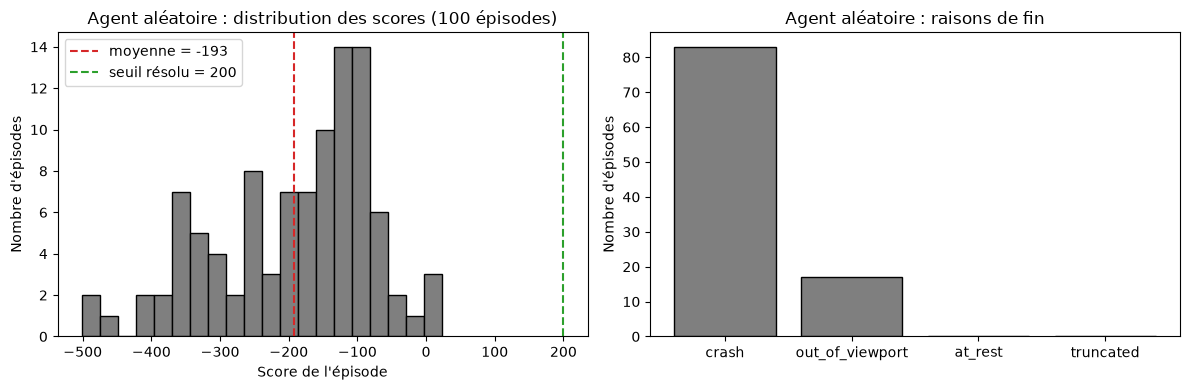

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

rewards = [log["reward"] for log in baseline_logs]
axes[0].hist(rewards, bins=20, color="tab:gray", edgecolor="black")
axes[0].axvline(np.mean(rewards), color="tab:red", linestyle="--", label=f"moyenne = {np.mean(rewards):.0f}")
axes[0].axvline(200, color="tab:green", linestyle="--", label="seuil résolu = 200")
axes[0].set_title("Agent aléatoire : distribution des scores (100 épisodes)")
axes[0].set_xlabel("Score de l'épisode")
axes[0].set_ylabel("Nombre d'épisodes")
axes[0].legend()

reasons = baseline_summary["end_reasons"]
axes[1].bar(list(reasons.keys()), list(reasons.values()), color="tab:gray", edgecolor="black")
axes[1].set_title("Agent aléatoire : raisons de fin")
axes[1].set_ylabel("Nombre d'épisodes")

plt.tight_layout()
plt.show()

**Lecture.** L'agent aléatoire se crashe presque toujours en quelques dizaines de steps, avec un score très négatif, et sort parfois du cadre. Il ne se pose jamais. C'est le plancher : la distance entre cette moyenne et 200 est ce que PPO doit apprendre.

## 6. Environnements vectorisés et autoreset

PPO apprend sur des *rollouts* : des lots de transitions collectées avec la politique courante. Faire tourner **plusieurs copies de l'environnement en parallèle** remplit ces lots plus vite et avec des situations plus variées (plusieurs épisodes à des stades différents dans le même lot).

Une copie qui finit son épisode doit repartir automatiquement : c'est l'**autoreset**. Gymnasium (≥ 1.1) propose deux modes :

| Mode | Ce qui se passe quand une copie finit | Conséquence pour PPO |
| --- | --- | --- |
| `NEXT_STEP` (par défaut) | le reset a lieu au step **suivant** : l'action envoyée à ce step est ignorée | une transition fantôme par fin d'épisode, à repérer et exclure du rollout |
| `SAME_STEP` | le reset a lieu **dans le même step** : on reçoit directement l'observation du nouvel épisode, et l'observation finale est dans `info["final_obs"]` | toutes les transitions sont valides ; l'observation finale reste disponible pour les épisodes tronqués |

**Choix : `SAME_STEP`.** Chaque step du rollout est une vraie transition, sans masque à gérer. Et pour un épisode **tronqué**, on dispose de l'observation finale pour estimer la valeur du futur : un épisode coupé par la limite de temps n'est pas réellement fini, la GAE doit en tenir compte.

La cellule ci-dessous le vérifie : au step où une copie finit, l'observation renvoyée est déjà celle du nouvel épisode, l'observation finale est dans `info`, et `get_end_reason` s'applique sans changement.

In [9]:
def make_vec_env(num_envs, seed):
    """Crée num_envs copies de LunarLander en parallèle, avec reset automatique dans le même step."""
    vec_env = gym.make_vec(
        ENV_ID,
        num_envs=num_envs,
        vectorization_mode="sync",
        vector_kwargs={"autoreset_mode": gym.vector.AutoresetMode.SAME_STEP},
    )
    vec_env.action_space.seed(seed)
    return vec_env


vec_env = make_vec_env(num_envs=8, seed=0)
obs, _ = vec_env.reset(seed=0)
print(f"Observations du lot : {obs.shape}  (num_envs, OBS_DIM)")

for step in range(1000):
    obs, rewards, terminated, truncated, info = vec_env.step(vec_env.action_space.sample())
    done = terminated | truncated
    if done.any():
        i = int(np.argmax(done))
        final_obs = info["final_obs"][i]
        reason = get_end_reason(final_obs, rewards[i], terminated[i], truncated[i])
        print(f"Step {step} : la copie {i} a fini ({reason}, reward finale {rewards[i]:.0f})")
        print(f"  x final (info['final_obs'])     = {final_obs[0]:+.3f}")
        print(f"  x renvoyé (déjà le nouvel épisode) = {obs[i][0]:+.3f}")
        break
vec_env.close()

Observations du lot : (8, 8)  (num_envs, OBS_DIM)
Step 65 : la copie 0 a fini (crash, reward finale -100)
  x final (info['final_obs'])     = +0.431
  x renvoyé (déjà le nouvel épisode) = -0.002


## 7. Actor-critic

PPO utilise deux fonctions apprises :

| Élément | Entrée → sortie | Rôle |
| --- | --- | --- |
| **Actor** (politique π) | état → 4 *logits*, transformés en probabilités par softmax | choisit l'action. On **tire** l'action selon ces probabilités pendant l'entraînement (l'exploration est intégrée), on prend la plus probable pendant l'évaluation |
| **Critic** (valeur V) | état → 1 nombre | estime le score que l'agent peut encore espérer depuis cet état avec sa politique actuelle. Il sert de point de comparaison pour juger les actions |

L'**avantage** d'une action, c'est la différence entre ce qu'elle a réellement rapporté et ce que le critic attendait. S'il est positif, l'action a fait mieux que prévu : on la rend plus probable. S'il est négatif, on la rend moins probable.

**Choix : deux réseaux séparés** (et non un tronc commun avec deux têtes). Les deux objectifs n'ont pas la même échelle : la value loss porte sur des scores de l'ordre de la centaine, la policy loss sur des avantages normalisés. Avec un tronc partagé, les gradients du critic peuvent écraser ceux de l'actor, et il faut alors pondérer finement les deux. Séparés, chacun apprend sa propre représentation. Le coût est négligeable ici : deux petits MLP.

**Architecture** : 2 couches cachées de 64 neurones, activation `tanh`, la taille classique pour un état de 8 valeurs. Les poids sont initialisés de façon orthogonale, avec un gain très faible (0.01) sur la sortie de l'actor : au départ, toutes les actions sont presque équiprobables, donc l'agent commence par explorer uniformément.

In [10]:
import copy
from collections import defaultdict

import torch.nn as nn
import torch.nn.functional as F
from torch.distributions import Categorical


def layer_init(layer, gain=np.sqrt(2)):
    """Initialisation orthogonale des poids, biais à zéro."""
    nn.init.orthogonal_(layer.weight, gain)
    nn.init.constant_(layer.bias, 0.0)
    return layer


def build_mlp(input_dim, hidden_sizes, output_dim, output_gain):
    """MLP avec activations tanh entre les couches cachées."""
    layers, last_dim = [], input_dim
    for size in hidden_sizes:
        layers += [layer_init(nn.Linear(last_dim, size)), nn.Tanh()]
        last_dim = size
    layers.append(layer_init(nn.Linear(last_dim, output_dim), gain=output_gain))
    return nn.Sequential(*layers)


class ActorCritic(nn.Module):
    """Actor (politique) et critic (valeur) : deux réseaux séparés."""

    def __init__(self, obs_dim, n_actions, hidden_sizes):
        super().__init__()
        self.actor = build_mlp(obs_dim, hidden_sizes, n_actions, output_gain=0.01)
        self.critic = build_mlp(obs_dim, hidden_sizes, 1, output_gain=1.0)

    def get_value(self, obs):
        """V(s) pour un lot d'états."""
        return self.critic(obs).squeeze(-1)

    def get_action_and_value(self, obs, action=None):
        """Tire une action (ou réévalue celle donnée) et renvoie action, log-proba, entropie, valeur."""
        distribution = Categorical(logits=self.actor(obs))
        if action is None:
            action = distribution.sample()
        return action, distribution.log_prob(action), distribution.entropy(), self.get_value(obs)

    def act_greedy(self, obs):
        """Action la plus probable, sans exploration (évaluation)."""
        with torch.no_grad():
            logits = self.actor(torch.as_tensor(obs, dtype=torch.float32))
        return int(torch.argmax(logits).item())

## 8. Rollout storage et GAE

PPO **n'utilise pas de replay buffer**. Il apprend uniquement sur les transitions que sa politique actuelle vient de jouer, puis il les jette : après la mise à jour, elles décrivent le comportement d'une politique qui n'existe plus.

Le rollout storage garde, pour chaque step et chaque environnement : l'état, l'action, sa log-probabilité au moment du tirage, la reward, la fin d'épisode et la valeur estimée par le critic. Après la collecte, on y ajoute les **avantages** et les **retours**.

**GAE (Generalized Advantage Estimation).** Pour chaque step, on calcule l'erreur de prédiction du critic à un pas :

δₜ = rₜ + γ · V(sₜ₊₁) · (1 − doneₜ) − V(sₜ)

L'avantage est ensuite une moyenne pondérée de ces erreurs sur les steps suivants, calculée en remontant le temps :

Aₜ = δₜ + γλ · (1 − doneₜ) · Aₜ₊₁

- **γ** (gamma) : poids du futur dans le score ;
- **λ** (lambda) : compromis biais/variance. λ = 0 ne regarde qu'un pas, et dépend donc beaucoup du critic (biais). λ = 1 additionne toutes les rewards réelles jusqu'à la fin, ce qui est très bruité (variance). 0.95 est le compromis standard ;
- le **retour** cible du critic est Rₜ = Aₜ + V(sₜ).

**Épisodes terminés vs tronqués.** `doneₜ = 1` coupe la chaîne entre deux épisodes : avec l'autoreset `SAME_STEP`, l'état suivant dans le buffer appartient déjà au nouvel épisode. La différence se joue sur la reward :
- **terminé** (crash, sortie du cadre, posé) : il n'y a pas de futur, la cible vaut juste rₜ ;
- **tronqué** (limite de 1000 steps) : le futur existait. On ajoute donc γ · V(observation finale) à la reward de ce step, avec l'observation finale fournie par `info["final_obs"]`. Sinon, on apprendrait au critic que planer jusqu'à la limite de temps ne vaut rien.

In [11]:
class RolloutStorage:
    """Stocke un rollout (n_steps x num_envs transitions) puis calcule avantages et retours."""

    def __init__(self, n_steps, num_envs, obs_dim):
        self.n_steps = n_steps
        self.obs = torch.zeros(n_steps, num_envs, obs_dim)
        self.actions = torch.zeros(n_steps, num_envs, dtype=torch.long)
        self.logprobs = torch.zeros(n_steps, num_envs)
        self.rewards = torch.zeros(n_steps, num_envs)
        self.dones = torch.zeros(n_steps, num_envs)
        self.values = torch.zeros(n_steps, num_envs)
        self.advantages = torch.zeros(n_steps, num_envs)
        self.returns = torch.zeros(n_steps, num_envs)
        self.step = 0

    def add(self, obs, action, logprob, reward, done, value):
        t = self.step
        self.obs[t] = obs
        self.actions[t] = action
        self.logprobs[t] = logprob
        self.rewards[t] = torch.as_tensor(reward, dtype=torch.float32)
        self.dones[t] = torch.as_tensor(done, dtype=torch.float32)
        self.values[t] = value
        self.step += 1

    def compute_gae(self, last_value, gamma, gae_lambda):
        """Avantages GAE et retours, en remontant le temps depuis la fin du rollout."""
        next_advantage = torch.zeros_like(last_value)
        for t in reversed(range(self.n_steps)):
            next_value = last_value if t == self.n_steps - 1 else self.values[t + 1]
            not_done = 1.0 - self.dones[t]
            delta = self.rewards[t] + gamma * next_value * not_done - self.values[t]
            next_advantage = delta + gamma * gae_lambda * not_done * next_advantage
            self.advantages[t] = next_advantage
        self.returns = self.advantages + self.values

    def flatten(self):
        """Tenseurs groupés par élément, aplatis en (n_steps * num_envs, ...), prêts à découper en mini-batches."""
        return {
            "obs": self.obs.reshape(-1, self.obs.shape[-1]),
            "actions": self.actions.reshape(-1),
            "logprobs": self.logprobs.reshape(-1),
            "advantages": self.advantages.reshape(-1),
            "returns": self.returns.reshape(-1),
        }

    def clear(self):
        """Vide le stockage (le rollout est jeté après chaque mise à jour)."""
        self.step = 0

## 9. Loss PPO et mise à jour

On réutilise chaque rollout pendant quelques **époques**, découpé en **mini-batches**. La loss combine trois termes :

**1. Policy loss clippée.** Le *ratio* rₜ = π_nouvelle(aₜ|sₜ) / π_ancienne(aₜ|sₜ) mesure de combien la mise à jour a changé la probabilité de l'action jouée. On maximise :

min( rₜ · Aₜ , clip(rₜ, 1 − ε, 1 + ε) · Aₜ )

Le clip coupe l'intérêt de pousser une action au-delà de ±ε (20 %) par rapport à la politique qui a collecté les données. Une seule mise à jour ne peut donc pas tout casser, et c'est ce qui rend PPO stable. Le `min` garde toujours la version la plus pessimiste.

**2. Value loss.** C'est la MSE entre la prédiction du critic V(sₜ) et le retour Rₜ.

**3. Bonus d'entropie.** L'entropie mesure à quel point la politique est aléatoire. La récompenser empêche l'actor de devenir certain trop tôt, avant d'avoir assez exploré.

loss = policy_loss + c_v · value_loss − c_e · entropie

Deux détails standards :
- les avantages sont **normalisés** par mini-batch (moyenne 0, écart-type 1). L'échelle du pas de gradient ne dépend alors plus de l'échelle des scores ;
- la norme du gradient est **plafonnée** (0.5) pour éviter les mises à jour explosives.

On suit aussi deux indicateurs de santé :
- `approx_kl`, l'écart entre l'ancienne et la nouvelle politique ;
- `clip_frac`, la part des transitions où le clip s'est déclenché.

S'ils s'envolent, les mises à jour sont trop agressives.

In [12]:
def ppo_update(agent, optimizer, storage, config):
    """Plusieurs époques de descente de gradient sur le rollout, par mini-batches."""
    batch = storage.flatten()
    batch_size = batch["obs"].shape[0]
    indices = np.arange(batch_size)
    clip = config["clip_range"]
    stats = defaultdict(list)

    for _ in range(config["n_epochs"]):
        np.random.shuffle(indices)
        for start in range(0, batch_size, config["minibatch_size"]):
            mb = indices[start:start + config["minibatch_size"]]
            _, new_logprob, entropy, new_value = agent.get_action_and_value(batch["obs"][mb], batch["actions"][mb])

            log_ratio = new_logprob - batch["logprobs"][mb]
            ratio = log_ratio.exp()
            advantages = batch["advantages"][mb]
            advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

            # 1. policy loss clippée (on minimise l'opposé de l'objectif)
            policy_loss = -torch.min(ratio * advantages, torch.clamp(ratio, 1 - clip, 1 + clip) * advantages).mean()
            # 2. value loss : MSE entre V(s) et le retour
            value_loss = F.mse_loss(new_value, batch["returns"][mb])
            # 3. bonus d'entropie
            entropy_bonus = entropy.mean()

            loss = policy_loss + config["value_coef"] * value_loss - config["entropy_coef"] * entropy_bonus
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), config["max_grad_norm"])
            optimizer.step()

            with torch.no_grad():
                stats["policy_loss"].append(policy_loss.item())
                stats["value_loss"].append(value_loss.item())
                stats["entropy"].append(entropy_bonus.item())
                stats["approx_kl"].append(((ratio - 1) - log_ratio).mean().item())
                stats["clip_frac"].append(((ratio - 1).abs() > clip).float().mean().item())

    return {key: float(np.mean(values)) for key, values in stats.items()}

## 10. Hyperparamètres

Première configuration, issue des valeurs usuelles de PPO sur des tâches de contrôle de cette taille. Elle sera ajustée un paramètre à la fois pendant la phase de tuning, et chaque changement sera documenté.

| Paramètre | Valeur | Raison |
| --- | --- | --- |
| `total_steps` | 1 000 000 | budget en **steps** plutôt qu'en épisodes : la durée d'un épisode varie de 60 à 1000 steps, alors qu'un step a toujours le même coût. C'est aussi l'unité de comparaison avec DQN |
| `num_envs` | 8 | 8 parties en parallèle : rollouts plus variés et collecte plus rapide |
| `rollout_steps` | 256 | 8 × 256 = 2048 transitions par mise à jour, assez pour couvrir plusieurs épisodes complets |
| `n_epochs` | 10 | chaque rollout est réutilisé 10 fois ; le clip empêche de trop s'en éloigner |
| `minibatch_size` | 64 | 32 mini-batches par époque, soit 320 pas de gradient par rollout |
| `learning_rate` | 3e-4 | valeur standard d'Adam pour PPO |
| `gamma` | 0.99 | horizon effectif d'environ 100 steps (1 / (1 − γ)) |
| `gae_lambda` | 0.95 | compromis biais/variance standard de la GAE |
| `clip_range` | 0.2 | ratio limité à [0.8, 1.2] |
| `value_coef` | 0.5 | poids de la value loss |
| `entropy_coef` | 0.01 | petite incitation à explorer |
| `max_grad_norm` | 0.5 | plafond de la norme du gradient |
| `hidden_sizes` | (64, 64) | voir section 7 |
| `eval_every` / `eval_episodes` | 10 / 10 | toutes les 10 mises à jour (≈ 20 000 steps), 10 épisodes sans exploration pour suivre les progrès et garder le meilleur modèle |

In [13]:
CONFIG = {
    "total_steps": 1_000_000,
    "num_envs": 8,
    "rollout_steps": 256,
    "n_epochs": 10,
    "minibatch_size": 64,
    "learning_rate": 3e-4,
    "gamma": 0.99,
    "gae_lambda": 0.95,
    "clip_range": 0.2,
    "value_coef": 0.5,
    "entropy_coef": 0.01,
    "max_grad_norm": 0.5,
    "hidden_sizes": (64, 64),
    "eval_every": 10,
    "eval_episodes": 10,
}
batch = CONFIG["num_envs"] * CONFIG["rollout_steps"]
print(f"{batch} transitions par rollout, {CONFIG['total_steps'] // batch} mises à jour au total")

2048 transitions par rollout, 488 mises à jour au total


## 11. Boucle d'entraînement

À chaque itération :
1. **Collecte** : `rollout_steps` steps dans les `num_envs` environnements avec la politique actuelle (actions tirées, donc exploration). Chaque fin d'épisode est loggée au format du contrat.
2. **GAE** : avantages et retours, en estimant la valeur de l'état où le rollout s'arrête.
3. **Mise à jour** PPO, puis le rollout est jeté.
4. **Évaluation périodique** : 10 épisodes sans exploration (action la plus probable), toujours sur les mêmes états de départ (seed fixe) pour que les scores soient comparables d'une évaluation à l'autre. Le meilleur modèle est conservé.

`global_step` compte les transitions **de tous les environnements** : 8 envs × 256 steps = 2048 steps par itération. C'est la même unité que DQN, ce qui rend la comparaison équitable.

In [14]:
def evaluate(agent, env, n_episodes, seed):
    """Score moyen sans exploration sur n_episodes (états de départ fixés par la seed)."""
    logs = run_episodes(env, agent.act_greedy, n_episodes, seed)
    return float(np.mean([log["reward"] for log in logs]))


def train(config, seed, verbose=True):
    """Entraîne un agent PPO et renvoie (agent au meilleur score d'évaluation, logs)."""
    set_seed(seed)
    num_envs, n_steps = config["num_envs"], config["rollout_steps"]
    envs = make_vec_env(num_envs, seed)
    eval_env = make_env()
    agent = ActorCritic(OBS_DIM, N_ACTIONS, config["hidden_sizes"])
    optimizer = torch.optim.Adam(agent.parameters(), lr=config["learning_rate"], eps=1e-5)
    storage = RolloutStorage(n_steps, num_envs, OBS_DIM)

    episode_logs, update_logs, eval_logs = [], [], []
    episode_returns = np.zeros(num_envs)
    episode_lengths = np.zeros(num_envs, dtype=int)
    best_score, best_state = -np.inf, None
    global_step, start = 0, time.time()
    n_updates = config["total_steps"] // (num_envs * n_steps)

    obs, _ = envs.reset(seed=seed)
    obs = torch.as_tensor(obs, dtype=torch.float32)

    for update in range(1, n_updates + 1):
        # 1. Collecte du rollout
        storage.clear()
        for _ in range(n_steps):
            with torch.no_grad():
                action, logprob, _, value = agent.get_action_and_value(obs)
            next_obs, reward, terminated, truncated, info = envs.step(action.numpy())
            global_step += num_envs
            done = terminated | truncated

            # Épisode tronqué : le futur existait, on ajoute sa valeur estimée à la reward
            reward_for_gae = reward.astype(np.float32)
            cut = np.where(truncated & ~terminated)[0]
            if len(cut) > 0:
                final_obs = torch.as_tensor(np.stack(info["final_obs"][cut]), dtype=torch.float32)
                with torch.no_grad():
                    reward_for_gae[cut] += config["gamma"] * agent.get_value(final_obs).numpy()
            storage.add(obs, action, logprob, reward_for_gae, done, value)

            # Logs des épisodes qui viennent de finir (reward réelle, pas celle de la GAE)
            episode_returns += reward
            episode_lengths += 1
            for i in np.where(done)[0]:
                episode_logs.append({
                    "episode": len(episode_logs),
                    "reward": float(episode_returns[i]),
                    "length": int(episode_lengths[i]),
                    "end_reason": get_end_reason(info["final_obs"][i], reward[i], terminated[i], truncated[i]),
                    "global_step": global_step,
                    "wall_time": time.time() - start,
                })
                episode_returns[i], episode_lengths[i] = 0.0, 0
            obs = torch.as_tensor(next_obs, dtype=torch.float32)

        # 2. GAE
        with torch.no_grad():
            last_value = agent.get_value(obs)
        storage.compute_gae(last_value, config["gamma"], config["gae_lambda"])

        # 3. Mise à jour PPO
        stats = ppo_update(agent, optimizer, storage, config)
        update_logs.append({"update": update, "global_step": global_step, "wall_time": time.time() - start, **stats})

        # 4. Évaluation périodique et meilleur modèle
        if update % config["eval_every"] == 0 or update == n_updates:
            score = evaluate(agent, eval_env, config["eval_episodes"], seed=10_000 + seed)
            eval_logs.append({"update": update, "global_step": global_step, "wall_time": time.time() - start, "mean_reward": score})
            if score >= best_score:
                best_score, best_state = score, copy.deepcopy(agent.state_dict())
            if verbose:
                recent = [log["reward"] for log in episode_logs[-100:]]
                print(f"step {global_step:>8d} | entraînement (100 derniers) {np.mean(recent):7.1f} | "
                      f"éval {score:7.1f} | meilleure éval {best_score:7.1f} | {time.time() - start:5.0f} s")

    envs.close()
    eval_env.close()
    agent.load_state_dict(best_state)
    logs = {"episodes": episode_logs, "updates": update_logs, "evals": eval_logs, "best_eval": best_score}
    return agent, logs

In [15]:
TRAIN_SEED = SEEDS[0]
train_path = RESULTS_DIR / f"train_seed{TRAIN_SEED}.json"

if TRAIN:
    agent, train_logs = train(CONFIG, seed=TRAIN_SEED)
    with open(train_path, "w") as f:
        json.dump({"meta": {"algo": "ppo", "seed": TRAIN_SEED, "config": CONFIG, "gymnasium": gym.__version__},
                   **train_logs}, f)
    print(f"Logs exportés dans {train_path}")
else:
    with open(train_path) as f:
        train_logs = json.load(f)
    print(f"Logs rechargés depuis {train_path} (TRAIN = False)")

Logs rechargés depuis results/ppo/train_seed0.json (TRAIN = False)


## 12. Courbes d'entraînement

Toutes les courbes sont tracées en fonction de `global_step` (transitions jouées), l'unité commune avec DQN.

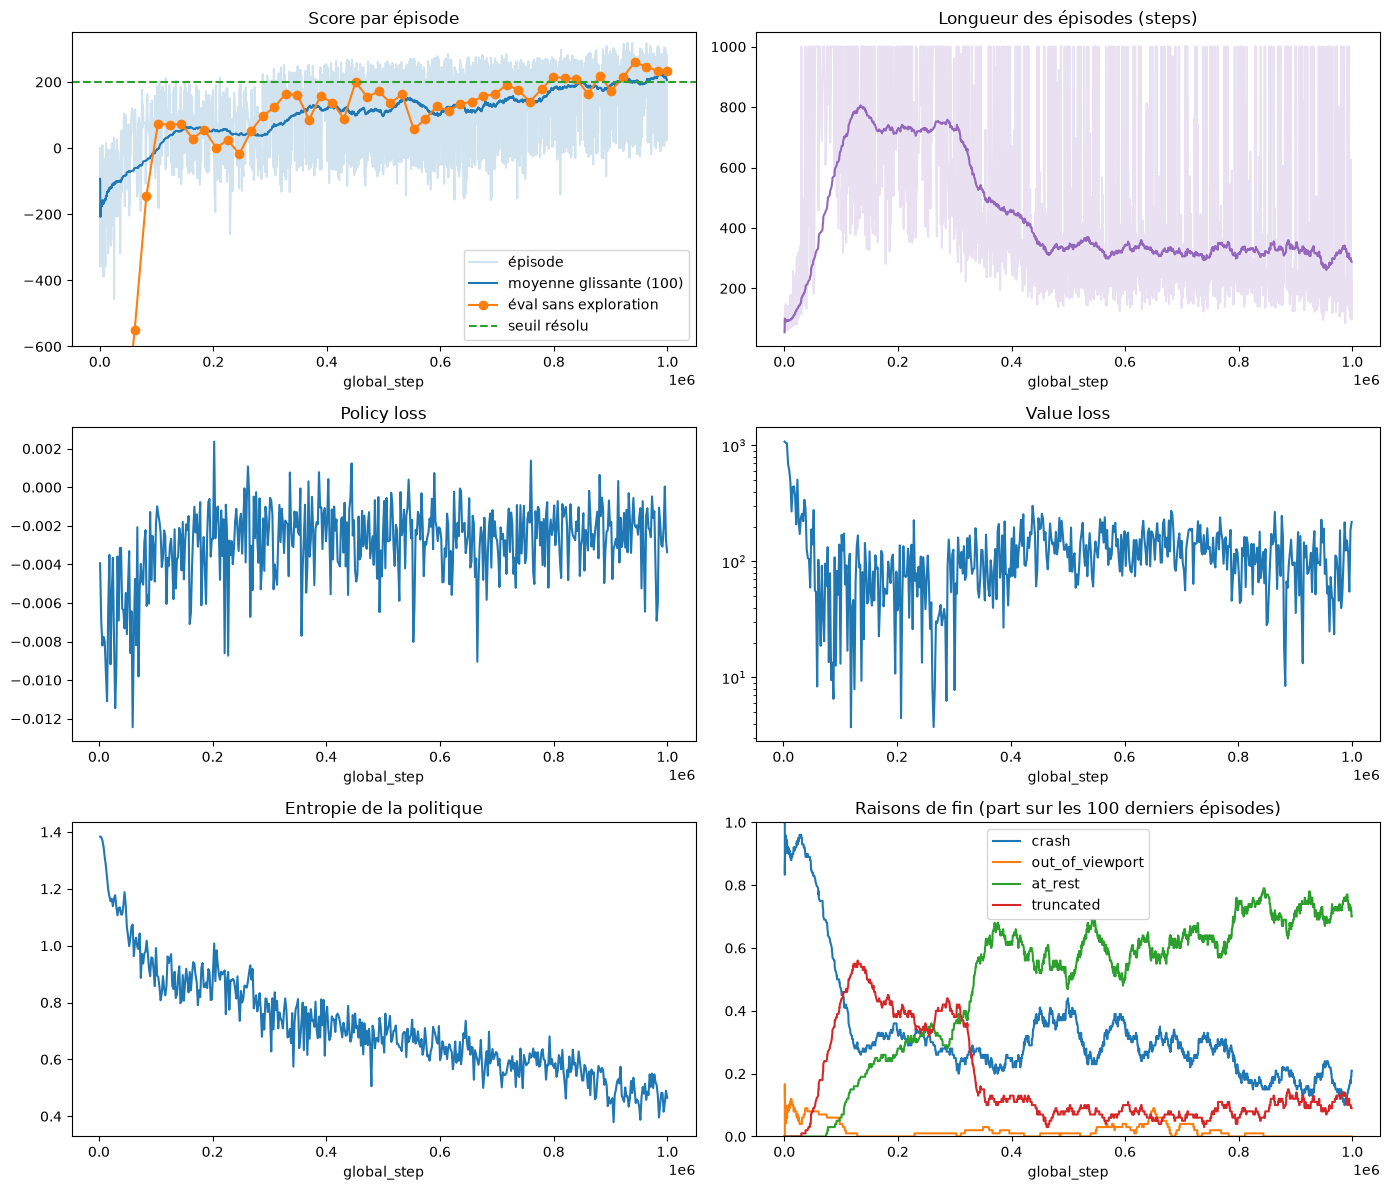

2655 épisodes d'entraînement : {'crash': 874, 'out_of_viewport': 53, 'truncated': 334, 'at_rest': 1394}
Meilleure évaluation pendant l'entraînement (10 épisodes) : 259.2


In [16]:
def moving_average(values, window=100):
    """Moyenne glissante (fenêtre plus courte au début)."""
    values = np.asarray(values, dtype=float)
    cumsum = np.cumsum(np.insert(values, 0, 0.0))
    out = np.empty_like(values)
    for i in range(len(values)):
        lo = max(0, i + 1 - window)
        out[i] = (cumsum[i + 1] - cumsum[lo]) / (i + 1 - lo)
    return out


def plot_training(logs):
    episodes, updates, evals = logs["episodes"], logs["updates"], logs["evals"]
    ep_steps = [e["global_step"] for e in episodes]
    up_steps = [u["global_step"] for u in updates]
    fig, axes = plt.subplots(3, 2, figsize=(14, 12))

    ax = axes[0, 0]
    rewards = [e["reward"] for e in episodes]
    ax.plot(ep_steps, rewards, alpha=0.2, color="tab:blue", label="épisode")
    ax.plot(ep_steps, moving_average(rewards), color="tab:blue", label="moyenne glissante (100)")
    ax.plot([e["global_step"] for e in evals], [e["mean_reward"] for e in evals], "o-", color="tab:orange", label="éval sans exploration")
    ax.axhline(200, color="tab:green", linestyle="--", label="seuil résolu")
    ax.set_title("Score par épisode")
    ax.set_ylim(-600, 350)
    ax.legend(loc="lower right")

    ax = axes[0, 1]
    lengths = [e["length"] for e in episodes]
    ax.plot(ep_steps, lengths, alpha=0.2, color="tab:purple")
    ax.plot(ep_steps, moving_average(lengths), color="tab:purple")
    ax.set_title("Longueur des épisodes (steps)")

    for ax, key, title in [(axes[1, 0], "policy_loss", "Policy loss"), (axes[1, 1], "value_loss", "Value loss"),
                           (axes[2, 0], "entropy", "Entropie de la politique")]:
        ax.plot(up_steps, [u[key] for u in updates])
        ax.set_title(title)
    axes[1, 1].set_yscale("log")

    ax = axes[2, 1]
    window = 100
    for reason in END_REASONS:
        flags = [1.0 if e["end_reason"] == reason else 0.0 for e in episodes]
        ax.plot(ep_steps, moving_average(flags, window), label=reason)
    ax.set_title(f"Raisons de fin (part sur les {window} derniers épisodes)")
    ax.set_ylim(0, 1)
    ax.legend()

    for ax in axes.flat:
        ax.set_xlabel("global_step")
    plt.tight_layout()
    plt.show()


plot_training(train_logs)
counts = Counter(e["end_reason"] for e in train_logs["episodes"])
print(f"{len(train_logs['episodes'])} épisodes d'entraînement : {dict(counts)}")
print(f"Meilleure évaluation pendant l'entraînement (10 épisodes) : {train_logs['best_eval']:.1f}")

## 13. Sauvegarde du modèle

Format du contrat : `{"state_dict", "config"}`. La config contient tout ce qu'il faut pour **reconstruire le réseau sans rien deviner** : c'est ce que `model.py` utilisera. On recharge ensuite le fichier et on rejoue quelques épisodes pour vérifier que la sauvegarde est complète.

In [17]:
MODEL_PATH = MODELS_DIR / "ppo.pt"


def save_checkpoint(agent, config, path):
    torch.save({
        "state_dict": agent.state_dict(),
        "config": {
            "algo": "ppo",
            "obs_dim": OBS_DIM,
            "n_actions": N_ACTIONS,
            "hidden_sizes": list(config["hidden_sizes"]),
            "shared": False,
            "activation": "tanh",
        },
    }, path)


def load_agent(path):
    checkpoint = torch.load(path, weights_only=False)
    cfg = checkpoint["config"]
    agent = ActorCritic(cfg["obs_dim"], cfg["n_actions"], cfg["hidden_sizes"])
    agent.load_state_dict(checkpoint["state_dict"])
    agent.eval()
    return agent


if TRAIN:
    save_checkpoint(agent, CONFIG, MODEL_PATH)
    print(f"Modèle sauvegardé dans {MODEL_PATH}")

reloaded = load_agent(MODEL_PATH)
check_env = make_env()
check_logs = run_episodes(check_env, reloaded.act_greedy, n_episodes=5, seed=123)
check_env.close()
for log in check_logs:
    print(f"épisode {log['episode']} : score {log['reward']:7.1f}  ({log['end_reason']}, {log['length']} steps)")

épisode 0 : score   274.0  (at_rest, 307 steps)
épisode 1 : score     4.4  (crash, 159 steps)
épisode 2 : score   270.4  (at_rest, 193 steps)
épisode 3 : score   286.2  (at_rest, 195 steps)
épisode 4 : score   251.9  (at_rest, 212 steps)


## 14. Suite

À venir : évaluation sur 100 épisodes consécutifs (moyenne, écart-type, distribution), résultats sur les seeds 0, 1 et 2, expérience comparative, comparaison avec DQN, conclusion.